<a href="https://colab.research.google.com/github/leonknst115/cognitive-computing-assignment1/blob/main/loan_approval.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [10]:
# task 2 - load data and print first 20 rows
df = pd.read_csv('loan_approval_dataset.csv', sep=';')
df.columns = df.columns.str.strip()  # column names have spaces in front
df['education'] = df['education'].str.strip()
df['self_employed'] = df['self_employed'].str.strip()
df['loan_status'] = df['loan_status'].str.strip()

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 250)
print(df.head(20))

    loan_id  no_of_dependents     education self_employed  income_annum  loan_amount  loan_term  cibil_score  residential_assets_value  commercial_assets_value  luxury_assets_value  bank_asset_value loan_status
0         1                 2      Graduate            No       9600000     29900000         12          778                   2400000                 17600000             22700000           8000000    Approved
1         2                 0  Not Graduate           Yes       4100000     12200000          8          417                   2700000                  2200000              8800000           3300000    Rejected
2         3                 3      Graduate            No       9100000     29700000         20          506                   7100000                  4500000             33300000          12800000    Rejected
3         4                 3      Graduate            No       8200000     30700000          8          467                  18200000                  3300

In [11]:
# size, missing values, approved vs rejected
print(df.shape)
print(df.isnull().sum())
print(df['loan_status'].value_counts())

(4269, 13)
loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64
loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64


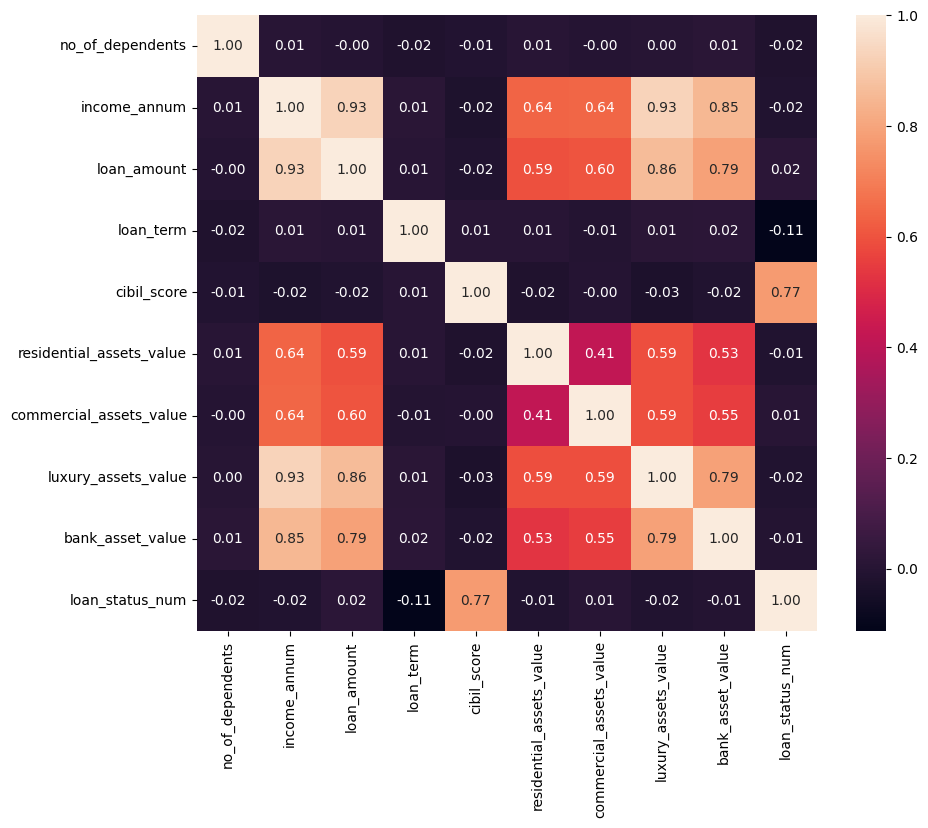

In [12]:
# task 4 - heatmap
df['loan_status_num'] = (df['loan_status'] == 'Approved').astype(int)  # approved = 1, rejected = 0
num = df.select_dtypes(include=np.number).drop(columns=['loan_id'])

corrmatrix = num.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corrmatrix, annot=True, fmt='.2f')
plt.show()

In [13]:
# task 5 - numerical features vs loan status
print(corrmatrix['loan_status_num'].sort_values())
print(df.groupby('loan_status')[num.columns].mean().T.round(2))

loan_term                  -0.113036
no_of_dependents           -0.018114
luxury_assets_value        -0.015465
income_annum               -0.015189
residential_assets_value   -0.014367
bank_asset_value           -0.006778
commercial_assets_value     0.008246
loan_amount                 0.016150
cibil_score                 0.770518
loan_status_num             1.000000
Name: loan_status_num, dtype: float64
loan_status                  Approved     Rejected
no_of_dependents                 2.47         2.54
income_annum               5025903.61   5113825.17
loan_amount               15247251.51  14946063.24
loan_term                       10.40        11.73
cibil_score                    703.46       429.47
residential_assets_value   7399811.75   7592498.45
commercial_assets_value    5001355.42   4926720.40
luxury_assets_value       15016603.92  15306943.58
bank_asset_value           4959525.60   5004959.70
loan_status_num                  1.00         0.00


In [14]:
# approval rate by cibil cutoff and by loan term
print(df.groupby(df['cibil_score'] >= 550)['loan_status'].value_counts(normalize=True))
print(df.groupby('loan_term')['loan_status_num'].mean())

cibil_score  loan_status
False        Rejected       0.896359
             Approved       0.103641
True         Approved       0.994767
             Rejected       0.005233
Name: proportion, dtype: float64
loan_term
2     0.779703
4     0.818792
6     0.575510
8     0.569948
10    0.525229
12    0.605263
14    0.590123
16    0.572816
18    0.609005
20    0.574209
Name: loan_status_num, dtype: float64


In [15]:
# task 5 - categorical feature: education
ct = pd.crosstab(df['education'], df['loan_status'])
print(ct)
print(pd.crosstab(df['education'], df['loan_status'], normalize='index'))

chi2, p, dof, exp = stats.chi2_contingency(ct)
print('chi2:', chi2, 'p-value:', p)

loan_status   Approved  Rejected
education                       
Graduate          1339       805
Not Graduate      1317       808
loan_status   Approved  Rejected
education                       
Graduate      0.624534  0.375466
Not Graduate  0.619765  0.380235
chi2: 0.08395754138250573 p-value: 0.7720042291016309


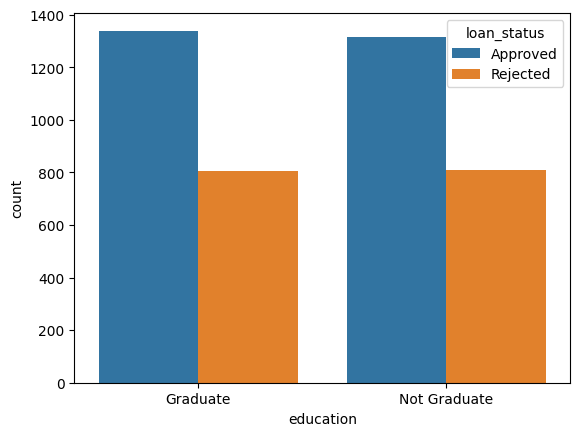

In [16]:
sns.countplot(data=df, x='education', hue='loan_status')
plt.show()